# POLAR tutorial

POLAR searches for the diffusion MRI protocol that lets a signal model recover its
parameters more reliably. For each candidate protocol it simulates signals, adds noise,
fits the model and measures the error of the fitted parameters. CMA-ES uses that error to
propose better protocols.

This tutorial uses CEXI as the example signal model and covers to:

1. define the tissue, the scanner limits and the noise
2. run an optimization
3. plot the loss
4. check the optimized protocol
5. compare it with a reference protocol

In [1]:
import json
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

import polar_dmri as polar

BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#898781"
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "font.size": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": "#c3c2b7",
        "axes.grid": True,
        "grid.color": "#e1e0d9",
        "grid.linewidth": 0.8,
        "lines.linewidth": 2,
        "legend.frameon": False,
    }
)

## 1. POLAR optimization needs:

- **Signal model and substrates:** the model to fit, and the tissue configurations the
  protocol should work for.
- **Scanner limits:** the hardware constraints of the scanner for which the protocol is optimized.
- **Noise:** here SNR 20 at TE = 70 ms, with 20 directions averaged per shell.

The substrate values below are examples.

In [2]:
model = polar.CEXI(T2=60e-3)

substrates = polar.make_substrate_grid(
    {
        "R": [3, 8],
        "Di": [0.7e-9, 1.3e-9],
        "De": [1.5e-9, 2.5e-9],
        "f": [0.45, 0.65],
        "kappa": [10, 20],
    }
)

constraints = polar.ScannerConstraints(G_bounds=(0.010, 0.180), te_max=120e-3)

noise = polar.RicianNoise(snr=20, te_ref=70e-3, t2=60e-3, n_directions=20)

print(f"{'Parameter':<10}{'Fit range':<24}Unit")
for parameter in model.parameters:
    fit_range = f"{parameter.low:g} to {parameter.high:g}"
    print(f"{parameter.name:<10}{fit_range:<24}{parameter.unit}")
print(f"\n{len(substrates)} substrates")

Parameter Fit range               Unit
R         1 to 15                 um
Di        3e-10 to 2e-09          m^2/s
De        1e-09 to 3.5e-09        m^2/s
f         0.3 to 0.85             
kappa     0.001 to 100            um/s

32 substrates


## 2. Run the optimization

`loss_parameters` sets which fitted parameters count in the loss.

The settings below make a smaller search than a full optimization to demonstrate
how POLAR is used.

In [3]:
run_dir = Path(tempfile.mkdtemp(prefix="polar_tutorial_"))

result = polar.optimize_protocol(
    model,
    substrates,
    n_shells=4,
    constraints=constraints,
    noise=noise,
    n_noise_realizations=2,
    loss_parameters=["R", "Di", "De", "f", "kappa"],
    settings=polar.OptimizerSettings(
        popsize=12, maxiter=300, min_generations=150, convergence_window=50
    ),
    seed=1,
    output_dir=run_dir,
    verbose=False,
)

print(f"Generations: {result.n_iterations}")
print(f"Stop reason: {result.stop_reason}")
print(f"Lowest loss: {result.loss:.4f}")
print("Output files:", ", ".join(sorted(path.name for path in run_dir.iterdir())))

Generations: 250
Stop reason: {'median_loss_plateau': 250}
Lowest loss: 0.0295
Output files: best_protocol.csv, metadata.json, population.jsonl, result.json, trace.jsonl


## 3. Plot the loss

`trace.jsonl` has one row per generation and `population.jsonl` has one row per candidate
protocol. Candidates that break the scanner limits get a large penalty instead of a loss.

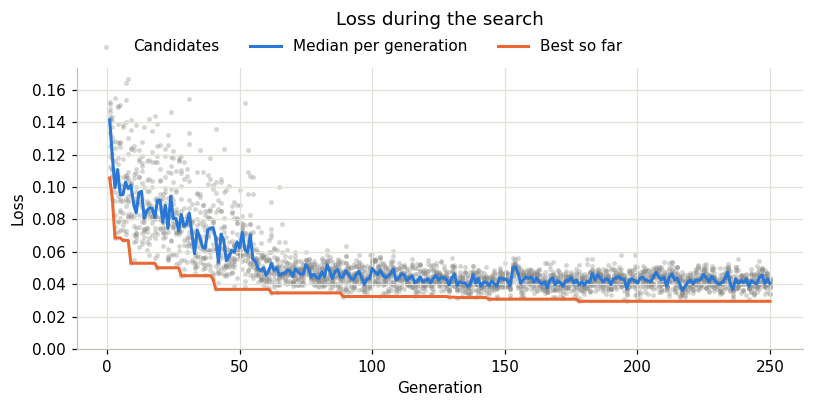

In [4]:
def read_jsonl(path):
    return [json.loads(line) for line in Path(path).read_text().splitlines()]


trace = read_jsonl(run_dir / "trace.jsonl")
population = [row for row in read_jsonl(run_dir / "population.jsonl") if row["loss"] <= 1]

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.scatter(
    [row["iter"] for row in population],
    [row["loss"] for row in population],
    s=10,
    color=GREY,
    alpha=0.35,
    linewidths=0,
    label="Candidates",
)
ax.plot(
    [row["iter"] for row in trace],
    [row["median_loss"] for row in trace],
    color=BLUE,
    label="Median per generation",
)
ax.plot(
    [row["iter"] for row in trace],
    [row["best_loss"] for row in trace],
    color=ORANGE,
    label="Best so far",
)
ax.set(xlabel="Generation", ylabel="Loss")
ax.set_ylim(bottom=0)
ax.set_title("Loss during the search", pad=28)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1), ncols=3)
fig.tight_layout()

## 4. Check protocol

`result.protocol` holds the best protocol, and it's also saved as `best_protocol.csv`.
Each shell is a PGSE sequence with two gradient pulses of duration δ, strength G and
separation Δ. All shells share one echo time, which the longest shell sets.

In [5]:
def print_protocol(protocol):
    print(f"{'Shell':<7}{'delta (ms)':>12}{'Delta (ms)':>12}{'G (mT/m)':>10}{'b (s/mm2)':>11}")
    for number, shell in enumerate(np.argsort(protocol.b_values), start=1):
        print(
            f"{number:<7}{protocol.delta[shell] * 1e3:>12.1f}{protocol.big_delta[shell] * 1e3:>12.1f}"
            f"{protocol.G[shell] * 1e3:>10.1f}{protocol.b_values[shell]:>11.0f}"
        )
    print(f"\nCommon TE: {protocol.te * 1e3:.1f} ms")


optimized = polar.PGSEProtocol.load_csv(run_dir / "best_protocol.csv")
print_protocol(optimized)

Shell    delta (ms)  Delta (ms)  G (mT/m)  b (s/mm2)
1               5.6         8.8     168.9        439
2              12.0        38.1      57.3       1156
3              12.3        15.4     179.7       3932
4              14.8        35.1     110.2       5777

Common TE: 60.1 ms


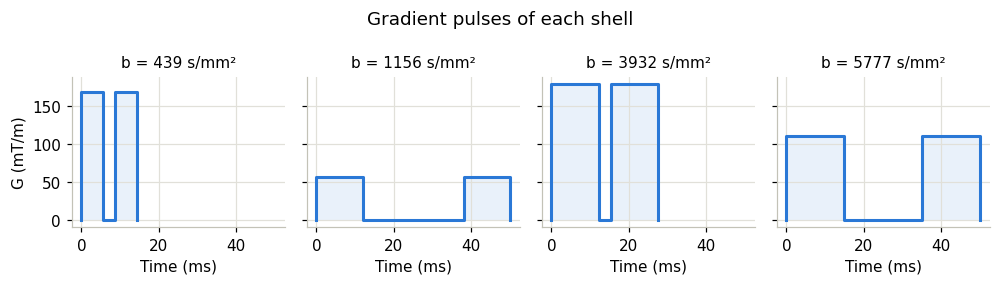

In [6]:
def plot_gradients(protocol):
    """One panel per shell, sorted by b-value, with shared axes."""
    order = np.argsort(protocol.b_values)
    fig, axes = plt.subplots(
        1, protocol.n_shells, figsize=(2.3 * protocol.n_shells, 2.6), sharex=True, sharey=True
    )
    for ax, shell in zip(np.atleast_1d(axes), order):
        delta = protocol.delta[shell] * 1e3
        big_delta = protocol.big_delta[shell] * 1e3
        G = protocol.G[shell] * 1e3
        time = [0, 0, delta, delta, big_delta, big_delta, big_delta + delta, big_delta + delta]
        gradient = [0, G, G, 0, 0, G, G, 0]
        ax.plot(time, gradient, color=BLUE, solid_joinstyle="round")
        ax.fill_between(time, gradient, color=BLUE, alpha=0.1, linewidth=0)
        ax.set_title(f"b = {protocol.b_values[shell]:.0f} s/mm²", fontsize=10)
        ax.set_xlabel("Time (ms)")
    np.atleast_1d(axes)[0].set_ylabel("G (mT/m)")
    fig.suptitle("Gradient pulses of each shell")
    fig.tight_layout()


plot_gradients(optimized)

## 5. Compare with reference protocol

The loss from the search is measured on the substrates and noise the optimization has seen. To
measure how well a protocol generalizes, evaluate it with `compare_protocols` on test
substrates whose parameter values differ from those used during the optimization search. All protocols get the same noise seeds to make the comparison fair.

As a reference, this uses a protocol with the same number of shells and equally spaced
b-values over the optimized protocol's range. All shells share the same δ and Δ, and the gradient strength changes.

In [7]:
b_targets = np.linspace(optimized.b_values.min(), optimized.b_values.max(), optimized.n_shells)
delta, big_delta = 10e-3, 30e-3
G = np.sqrt(b_targets / polar.pgse_b_value(delta, big_delta, 1.0))

reference = polar.PGSEProtocol(
    delta=np.full(optimized.n_shells, delta),
    big_delta=np.full(optimized.n_shells, big_delta),
    G=G,
)
assert constraints.is_feasible(reference)
print_protocol(reference)

Shell    delta (ms)  Delta (ms)  G (mT/m)  b (s/mm2)
1              10.0        30.0      47.9        439
2              10.0        30.0     107.8       2218
3              10.0        30.0     144.7       3998
4              10.0        30.0     174.0       5777

Common TE: 50.0 ms


In [8]:
test_substrates = polar.make_substrate_grid(
    {"R": [4, 6, 10], "Di": [0.8e-9, 1.2e-9], "De": [1.6e-9, 2.4e-9], "f": [0.4, 0.6], "kappa": [15, 25]}
)

results = polar.compare_protocols(
    model,
    {"Optimized": optimized, "Reference": reference},
    test_substrates,
    noise,
    n_noise_realizations=20,
)

print(f"{'Protocol':<12}{'Loss':>8}   Normalized RMSE per parameter")
for name, evaluation in results.items():
    per_parameter = "  ".join(
        f"{parameter}={stats['normalized_rmse']:.3f}"
        for parameter, stats in evaluation.summary().items()
    )
    print(f"{name:<12}{evaluation.loss():>8.4f}   {per_parameter}")

Protocol        Loss   Normalized RMSE per parameter
Optimized     0.0589   R=0.048  Di=0.323  De=0.127  f=0.139  kappa=0.390
Reference     0.0996   R=0.191  Di=0.369  De=0.252  f=0.232  kappa=0.456


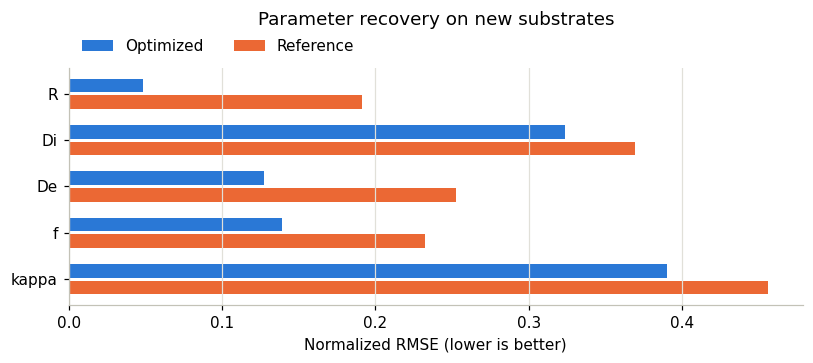

In [ ]:
names = model.parameter_names
positions = np.arange(len(names))
height = 0.3

fig, ax = plt.subplots(figsize=(7.5, 3.4))
for offset, (name, color) in zip([-0.18, 0.18], [("Optimized", BLUE), ("Reference", ORANGE)]):
    summary = results[name].summary()
    ax.barh(
        positions + offset,
        [summary[parameter]["normalized_rmse"] for parameter in names],
        height,
        color=color,
        label=name,
    )
ax.set_yticks(positions, names)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("Normalized RMSE (lower is better)")
ax.set_title("Parameter recovery on new substrates", pad=28)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1), ncols=2)
fig.tight_layout()